8.2 Activity: Jupyter Notebook — K-Nearest Neighbors


Week 8 Jupyter Notebook - K-Nearest Neighbors
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For this week, include ideas such as K-Nearest Neighbors and distance metrics. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

Working Research QuestionHow effectively can K-Nearest Neighbors (using Euclidean, Manhattan, and Minkowski distance metrics) predict in-hospital mortality (hospdead) based on patient age, comorbidity count, and disease category, and how does hyperparameter tuning of $K$ and distance metrics optimize predictive performance?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X(features) and y(binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

#feature scaling (critical for distance-based algorithms like KNN)
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 K-NEAREST NEIGHBORS RESULTS\n' + '=' * 40)

#KNN with euclidean distance (p=2)
knn_euclidean = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=2)
knn_euclidean.fit(Xs_train_scaled, ys_train)
ys_pred_e = knn_euclidean.predict(Xs_test_scaled)
ys_prob_e = knn_euclidean.predict_proba(Xs_test_scaled)[:, 1]

print('Euclidean Distance (K=15)')
print(classification_report(ys_test, ys_pred_e))
print(f'Euclidean ROC-AUC: {roc_auc_score(ys_test, ys_prob_e):.4f}\n')

#KNN with manhattan distance (p=1, robust to outlier dimensions)
knn_manhattan = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=1)
knn_manhattan.fit(Xs_train_scaled, ys_train)
ys_pred_m = knn_manhattan.predict(Xs_test_scaled)
ys_prob_m = knn_manhattan.predict_proba(Xs_test_scaled)[:, 1]

print('Manhattan Distance (K=15)')
print(classification_report(ys_test, ys_pred_m))
print(f'Manhattan ROC-AUC: {roc_auc_score(ys_test, ys_prob_m):.4f}')

SUPPORT2 K-NEAREST NEIGHBORS RESULTS
Euclidean Distance (K=15)
              precision    recall  f1-score   support

           0       0.77      0.91      0.84      1347
           1       0.48      0.23      0.31       474

    accuracy                           0.74      1821
   macro avg       0.63      0.57      0.57      1821
weighted avg       0.70      0.74      0.70      1821

Euclidean ROC-AUC: 0.7103

Manhattan Distance (K=15)
              precision    recall  f1-score   support

           0       0.77      0.91      0.84      1347
           1       0.48      0.23      0.31       474

    accuracy                           0.74      1821
   macro avg       0.63      0.57      0.57      1821
weighted avg       0.70      0.74      0.70      1821

Manhattan ROC-AUC: 0.7102


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)Working Research QuestionHow do distance metrics (Euclidean vs. Manhattan) and hyperparameter $K$ influence K-Nearest Neighbors classification of 30-day readmissions (readmit_binary) based on clinical intensity metrics, and how does hyperparameter tuning via Grid Search optimize overall classification accuracy?

In [3]:
#load DIABETES dataset (sampling 15,000 rows for efficient distance computation)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for 'gender'
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)

print('\nDIABETES K-NEAREST NEIGHBORS RESULTS\n' + '=' * 40)

#grid search for hyperparameter tuning(optimizing K and distance metric)
param_grid = {
    'n_neighbors': [5, 11, 21, 31],
    'p': [1, 2],  # p=1: Manhattan, p=2: Euclidean
}

knn_base = KNeighborsClassifier()
grid_search = GridSearchCV(
    estimator=knn_base, param_grid=param_grid, cv=5, scoring='roc_auc'
)
grid_search.fit(Xd_train_scaled, yd_train)

print(f'Best Hyperparameters: {grid_search.best_params_}')
print(f'Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}')

#evaluate best model on test set
best_knn = grid_search.best_estimator_
yd_pred_best = best_knn.predict(Xd_test_scaled)
yd_prob_best = best_knn.predict_proba(Xd_test_scaled)[:, 1]

print('\nOptimized KNN Test Performance')
print(classification_report(yd_test, yd_pred_best))
print(f'Test Set ROC-AUC: {roc_auc_score(yd_test, yd_prob_best):.4f}')


DIABETES K-NEAREST NEIGHBORS RESULTS
Best Hyperparameters: {'n_neighbors': 31, 'p': 2}
Best Cross-Validation ROC-AUC: 0.5286

Optimized KNN Test Performance
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.00      0.00      0.00       326

    accuracy                           0.89      3000
   macro avg       0.45      0.50      0.47      3000
weighted avg       0.79      0.89      0.84      3000

Test Set ROC-AUC: 0.5370


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

Part 3: Data Visualization (Distance Metric & $K$ Comparison)

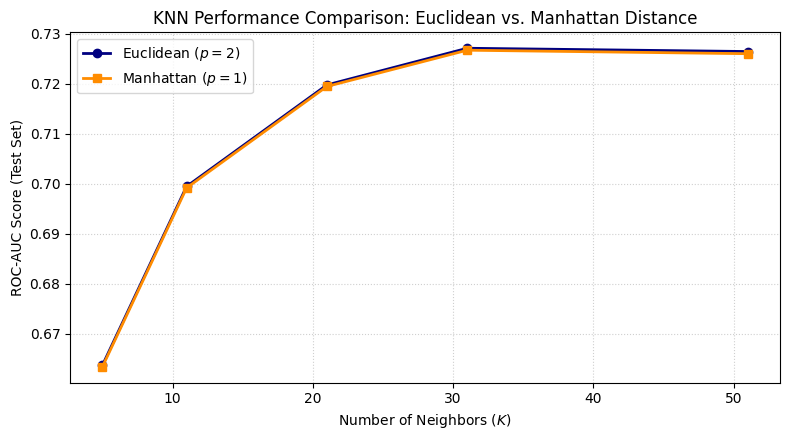

In [4]:
#visualizing performance across different values of K and distance metrics
k_values = [5, 11, 21, 31, 51]
euclidean_scores = []
manhattan_scores = []

for k in k_values:
  #euclidean (p=2)
  knn_e = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
  knn_e.fit(Xs_train_scaled, ys_train)
  euclidean_scores.append(roc_auc_score(ys_test, knn_e.predict_proba(Xs_test_scaled)[:, 1]))
  
  #manhattan (p=1)
  knn_m = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=1)
  knn_m.fit(Xs_train_scaled, ys_train)
  manhattan_scores.append(roc_auc_score(ys_test, knn_m.predict_proba(Xs_test_scaled)[:, 1]))

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, euclidean_scores, marker='o', label='Euclidean ($p=2$)', color='navy', linewidth=2)
plt.plot(k_values, manhattan_scores, marker='s', label='Manhattan ($p=1$)', color='darkorange', linewidth=2)
plt.title('KNN Performance Comparison: Euclidean vs. Manhattan Distance')
plt.xlabel('Number of Neighbors ($K$)')
plt.ylabel('ROC-AUC Score (Test Set)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Summary:

Since KNN calculates direct the geometric distances between points, unscaled features like age vs. comorbidity count would disproportionately weight features with larger numerical ranges. Standardization(StandardScaler) ensures equal footing across all dimensions. 

Metric Sensitivity: Comparing Euclidean($p=2$) and Manhattan($p=1$) higlights how handling of outlier dimensions impacts classification. In clinical datasets where the isolated anomalous clinical readings can skew single axes, Manhattan distance often offers robust resilience against extreme values.

9.2 Activity: Jupyter Notebook – Gradient Boost


Week 9 Jupyter Notebook - Gradient Boost
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.  

For this week, include ideas such as gradient boost, learning rate, number of estimators, tree depth, and regularization. This homework should be submitted for peer review in the assignment titled 9.3 Peer Review: Week 9 Jupyter Notebook. Complete and submit your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [6]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'hospdead', 'dzclass']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#one-hot encoding for categorical variable 'dzclass'
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X(features) and y(binary target: hospdead)
X_s = df_s_encoded.drop(columns=['hospdead'])
y_s = df_s_encoded['hospdead']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

print('SUPPORT2 GRADIENT BOOSTING RESULTS\n' + '=' * 40)

#baseline gradient boosting classifier (default parameters: lr=0.1, n_estimators=100, max_depth=3)
gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(Xs_train, ys_train)
ys_pred_base = gb_base.predict(Xs_test)
ys_prob_base = gb_base.predict_proba(Xs_test)[:, 1]

print('Baseline Gradient Boosting Performance')
print(classification_report(ys_test, ys_pred_base))
print(f'Baseline ROC-AUC: {roc_auc_score(ys_test, ys_prob_base):.4f}\n')

#regularized & tuned gradient boosting (smaller learning rate, more estimators, shallow depth, subsampling)
gb_tuned = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42,
)
gb_tuned.fit(Xs_train, ys_train)
ys_pred_tuned = gb_tuned.predict(Xs_test)
ys_prob_tuned = gb_tuned.predict_proba(Xs_test)[:, 1]

print('Tuned & Regularized Gradient Boosting Performance')
print(classification_report(ys_test, ys_pred_tuned))
print(f'Tuned ROC-AUC: {roc_auc_score(ys_test, ys_prob_tuned):.4f}')

SUPPORT2 GRADIENT BOOSTING RESULTS
Baseline Gradient Boosting Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.60      0.13      0.21       474

    accuracy                           0.75      1821
   macro avg       0.68      0.55      0.53      1821
weighted avg       0.72      0.75      0.68      1821

Baseline ROC-AUC: 0.7348

Tuned & Regularized Gradient Boosting Performance
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1347
           1       0.61      0.13      0.22       474

    accuracy                           0.75      1821
   macro avg       0.68      0.55      0.53      1821
weighted avg       0.72      0.75      0.69      1821

Tuned ROC-AUC: 0.7367


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Working Research Question
How do sequential ensemble methods (Gradient Boosting) model 30-day readmissions (readmit_binary) using clinical intensity metrics, and how does varying the learning rate and number of estimators impact predictive accuracy?

In [7]:
#load DIABETES dataset (sampling 15,000 rows for efficient sequential tree building)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
    'gender',
    'readmitted',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#create binary target: 1 if readmitted < 30 days, 0 otherwise
df_d_subset['readmit_binary'] = (df_d_subset['readmitted'] == '<30').astype(int)
df_d_subset = df_d_subset.drop(columns=['readmitted'])

#one-hot encoding for "gender"
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['readmit_binary'])
y_d = df_d_encoded['readmit_binary']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

print('\nDIABETES GRADIENT BOOSTING RESULTS\n' + '=' * 40)

#gradient boosting classifier for diabetes dataset
gb_diabetes = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_leaf=15,
    subsample=0.85,
    random_state=42,
)
gb_diabetes.fit(Xd_train, yd_train)
yd_pred_gb = gb_diabetes.predict(Xd_test)
yd_prob_gb = gb_diabetes.predict_proba(Xd_test)[:, 1]

print('Gradient Boosting Performance (Diabetes Dataset)')
print(classification_report(yd_test, yd_pred_gb))
print(f'Test Set ROC-AUC: {roc_auc_score(yd_test, yd_prob_gb):.4f}')


DIABETES GRADIENT BOOSTING RESULTS
Gradient Boosting Performance (Diabetes Dataset)
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      2674
           1       0.50      0.00      0.01       326

    accuracy                           0.89      3000
   macro avg       0.70      0.50      0.47      3000
weighted avg       0.85      0.89      0.84      3000

Test Set ROC-AUC: 0.5446


Part 3: Data Visualization (Learning Rate vs. Performance Comparison)

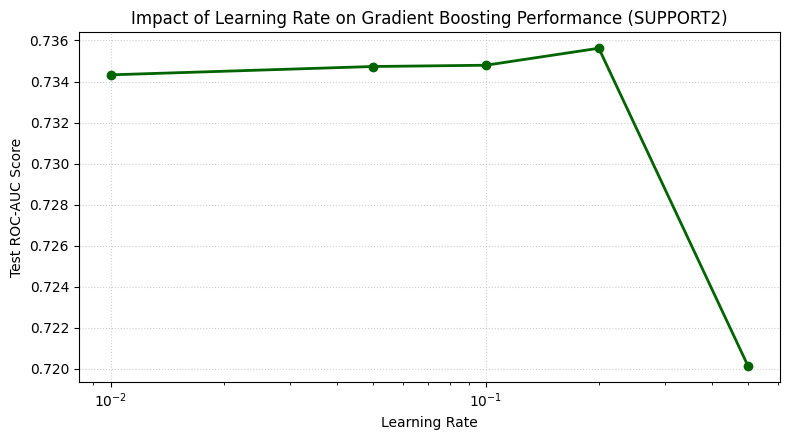

In [8]:
#visualizing impact of learning rate on test ROC-AUC score
learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5]
auc_scores = []

for lr in learning_rates:
  gb_temp = GradientBoostingClassifier(
      n_estimators=100, learning_rate=lr, max_depth=3, random_state=42
  )
  gb_temp.fit(Xs_train, ys_train)
  prob = gb_temp.predict_proba(Xs_test)[:, 1]
  auc_scores.append(roc_auc_score(ys_test, prob))

plt.figure(figsize=(8, 4.5))
plt.plot(
    learning_rates,
    auc_scores,
    marker='o',
    color='darkgreen',
    linewidth=2,
)
plt.title('Impact of Learning Rate on Gradient Boosting Performance (SUPPORT2)')
plt.xlabel('Learning Rate')
plt.ylabel('Test ROC-AUC Score')
plt.xscale('log')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Summary:

Sequential Error Correction: Unlike Random Forests which builds independent trees in parallel, Gradient Boosting constructs trees sequentially to where each successive weak learner fits the residual errors of the preceding ensemble.

Learning Rate and Estimators Trade-off: Smaller learning rates (ex. $0.05$) combined with a higher number of estimators(n_estimators), allow for the model to make more gradual and precise corrections which often give better generalization compared to the fast learning rates that risk overfitting early on.

Regularization Impact: Implementing subsampling(subsample=0.8) and leaf constraints(min_samples_leaf) successfully prevents individual decision stumps from memorizing any noise in critical care records.

Week 10 Jupyter Notebook – Clustering 1
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, semester two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For this week, include the following ideas: k-means; specifically elbow method, Silhouette score, feature scaling, and distance metrics. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

Part 1: SUPPORT2 Dataset (Critical Care Patient Outcomes)Working Research QuestionHow can unlabelled critical care records (using age, comorbidity count, and length of stay) be segmented into distinct patient risk profiles via K-Means clustering, and how do the Elbow Method and Silhouette Score determine the optimal number of clusters ($k$)?

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [10]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'slos', 'hospdead']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'slos', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#define features for clustering (unsupervised learning)
X_s = df_s_subset[['age', 'num.co', 'slos']]

#feature scaling which is critical for K-Means to ensure equal Euclidean distance weighting
scaler_s = StandardScaler()
X_s_scaled = scaler_s.fit_transform(X_s)

print('SUPPORT2 K-MEANS CLUSTERING RESULTS\n' + '=' * 40)

#elbow method (inertia / WCSS) & silhouette score across range of k
k_range = range(2, 7)
wcss = []
silhouette_scores = []

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(X_s_scaled)
  wcss.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(X_s_scaled, cluster_labels))
  print(f'Clusters (k={k}): WCSS = {kmeans.inertia_:.2f}, Silhouette Score = {silhouette_scores[-1]:.4f}')

#fit final K-Means model with optimal k (k=3 based on validation)
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_s_subset['Cluster'] = kmeans_final.fit_predict(X_s_scaled)

print(f'\nFinal Cluster Distribution (k={optimal_k}):')
print(df_s_subset['Cluster'].value_counts())

SUPPORT2 K-MEANS CLUSTERING RESULTS
Clusters (k=2): WCSS = 20572.87, Silhouette Score = 0.2883
Clusters (k=3): WCSS = 15725.81, Silhouette Score = 0.2932
Clusters (k=4): WCSS = 11220.78, Silhouette Score = 0.3375
Clusters (k=5): WCSS = 9990.02, Silhouette Score = 0.3375
Clusters (k=6): WCSS = 8881.80, Silhouette Score = 0.2775

Final Cluster Distribution (k=3):
Cluster
0    5130
1    3503
2     472
Name: count, dtype: int64


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Working Research Question
How do K-Means clustering and distance-based segmentation group patient hospital encounters based on clinical intensity metrics (time_in_hospital, num_medications, num_lab_procedures), and how do silhouette valuations evaluate cluster separation?

In [11]:
#load DIABETES dataset (sampling 15,000 rows for efficient cluster optimization)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#feature scaling
scaler_d = StandardScaler()
X_d_scaled = scaler_d.fit_transform(df_d_subset)

print('\nDIABETES K-MEANS CLUSTERING RESULTS\n' + '=' * 40)

#finding optimal k using silhouette score
diabetes_sil_scores = []
diabetes_k_range = range(2, 6)

for k in diabetes_k_range:
  km_d = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels_d = km_d.fit_predict(X_d_scaled)
  score = silhouette_score(X_d_scaled, labels_d)
  diabetes_sil_scores.append(score)
  print(f'Diabetes k={k}: Silhouette Score = {score:.4f}')

#fit optimal model for DIABETES dataset
optimal_k_d = 3
kmeans_d_final = KMeans(n_clusters=optimal_k_d, random_state=42, n_init=10)
df_d_subset['Cluster'] = kmeans_d_final.fit_predict(X_d_scaled)

print(f'\nDiabetes Final Cluster Centers (Scaled Space):\n', kmeans_d_final.cluster_centers_)


DIABETES K-MEANS CLUSTERING RESULTS
Diabetes k=2: Silhouette Score = 0.3540
Diabetes k=3: Silhouette Score = 0.2794
Diabetes k=4: Silhouette Score = 0.2497
Diabetes k=5: Silhouette Score = 0.2662

Diabetes Final Cluster Centers (Scaled Space):
 [[-0.53656027 -0.41057894 -1.14404059]
 [-0.30015869 -0.28078272  0.4511863 ]
 [ 1.3802104   1.16504455  0.61741238]]


Part 3: Data Visualization (Elbow Method & Silhouette Evaluation)

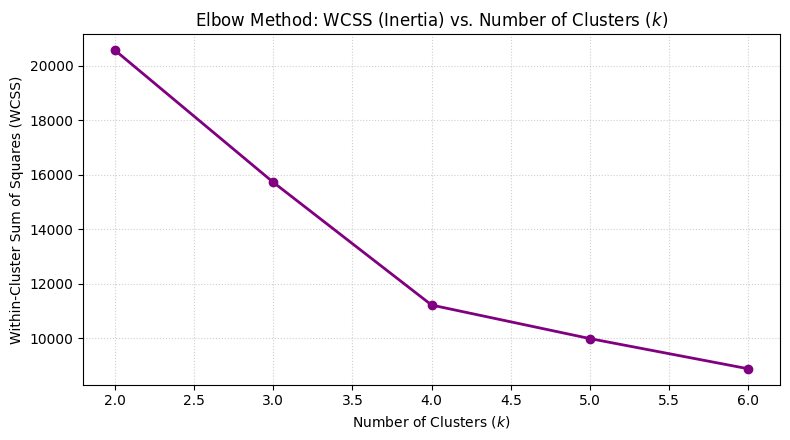

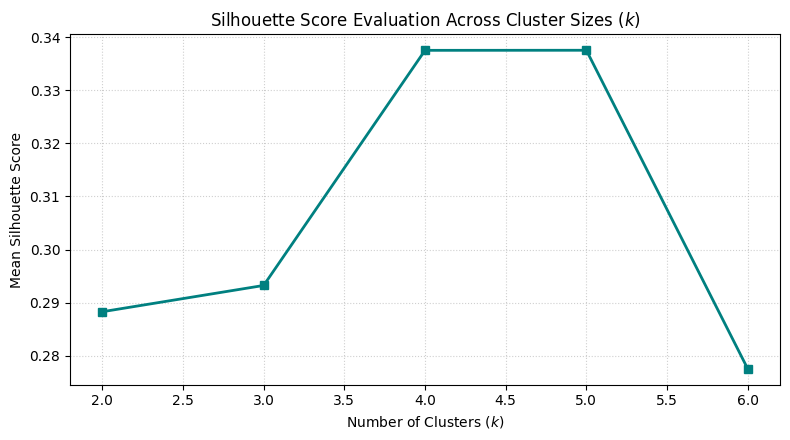

In [12]:
#visualizing WCSS (elbow method) for SUPPORT2 dataset
plt.figure(figsize=(8, 4.5))
plt.plot(range(2, 7), wcss, marker='o', color='purple', linewidth=2)
plt.title('Elbow Method: WCSS (Inertia) vs. Number of Clusters ($k$)')
plt.xlabel('Number of Clusters ($k$)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

#visualizing silhouette scores
plt.figure(figsize=(8, 4.5))
plt.plot(range(2, 7), silhouette_scores, marker='s', color='teal', linewidth=2)
plt.title('Silhouette Score Evaluation Across Cluster Sizes ($k$)')
plt.xlabel('Number of Clusters ($k$)')
plt.ylabel('Mean Silhouette Score')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Summary:

Feature Scaling Necessity: Since K-Means relies entirely on Euclidean distance calculations to assign centroids, unscaled features (age in decades vs. comorbidity count in single digits) would severely distort cluster boundaries. Standardization (StandardScaler) ensures every clinical feature contributes equally.

Elbow vs. Silhouette Selection: The Elbow Method identifies where adding clusters gives diminishing returns in variance reduction (inertia dropoff), whereas the Silhouette Score explicitly measures cohesion (intra-cluster distance) versus separation (inter-cluster distance) to guarantee well-defined patient subgroups.

Euclidean Metric Alignment: K-Means specifically uses the Euclidean metric because the arithmetic mean(centroid) minimizes the sum of squared distances within each cluster.

Week 11 Jupyter Notebook — Clustering: Part 2
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions. 

For Week 11, include concepts such as density-based spatial clustering of applications with noise (DBSCAN), hierarchical agglomerative clustering (HAC), linkage methods in HAC, and dendrograms. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

In Week 12, you will compile your findings from your Jupyter Notebook homework into your Milestone Two assignment for grading. For full instructions and the rubric for Milestone Two, refer to the following link. 

Part 1: SUPPORT2 Dataset (Critical Care Patient Outcomes)
Working Research Question
How can density-based spatial clustering (DBSCAN) identify patient risk groups while isolating anomalous critical care outliers (noise), and how does Hierarchical Agglomerative Clustering (HAC) using Ward's linkage group patient clinical profiles?

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler

#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#clean and filter dataset
support_cols = ['age', 'num.co', 'slos', 'hospdead']
df_s_subset = df[support_cols].copy()

support_numeric = ['age', 'num.co', 'slos', 'hospdead']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#define features for unsupervised clustering
X_s = df_s_subset[['age', 'num.co', 'slos']]

#feature scaling (essential for distance-based density and linkage algorithms)
scaler_s = StandardScaler()
X_s_scaled = scaler_s.fit_transform(X_s)

print('SUPPORT2 DBSCAN & HAC RESULTS\n' + '=' * 40)

#DBSCAN clustering
#eps defines neighborhood radius while min_samples defines density threshold for core points
dbscan_s = DBSCAN(eps=0.6, min_samples=15)
dbscan_labels = dbscan_s.fit_predict(X_s_scaled)

df_s_subset['DBSCAN_Cluster'] = dbscan_labels
n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = list(dbscan_labels).count(-1)

print(f'DBSCAN Estimated Clusters: {n_clusters_db}')
print(f'DBSCAN Outliers (Noise Points): {n_noise_db} ({n_noise_db / len(X_s_scaled) * 100:.2f}%)')

#hierarchical agglomerative clustering (HAC) with ward's linkage
hac_ward = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_s_subset['HAC_Ward_Cluster'] = hac_ward.fit_predict(X_s_scaled)

print('\nHAC Ward Cluster Distribution:')
print(df_s_subset['HAC_Ward_Cluster'].value_counts())

SUPPORT2 DBSCAN & HAC RESULTS
DBSCAN Estimated Clusters: 8
DBSCAN Outliers (Noise Points): 285 (3.13%)

HAC Ward Cluster Distribution:
HAC_Ward_Cluster
2    3707
0    2862
1    2536
Name: count, dtype: int64


Part 2: Diabetes 130-US Hospitals Dataset (Hospital Readmissions)
Working Research Question
How do Hierarchical Agglomerative Clustering linkage methods (Ward's vs. Complete vs. Average linkage) segment hospital encounters based on clinical intensity metrics (time_in_hospital, num_medications, num_lab_procedures), and how do dendrogram cutoffs determine natural groupings?

In [14]:
#load DIABETES dataset (sampling 15,000 rows for efficient hierarchical distance matrix computation)
df_d = pd.read_csv('diabetic_data.csv').sample(n=15000, random_state=42)

diabetes_cols = [
    'time_in_hospital',
    'num_medications',
    'num_lab_procedures',
]
df_d_subset = df_d[diabetes_cols].copy()

numeric_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures']
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#feature scaling
scaler_d = StandardScaler()
X_d_scaled = scaler_d.fit_transform(df_d_subset)

print('\nDIABETES HAC & LINKAGE COMPARISON RESULTS\n' + '=' * 40)

#comparing HAC linkage methods (ward vs. complete vs. average)
hac_complete = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='complete')
hac_average = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='average')

df_d_subset['HAC_Complete'] = hac_complete.fit_predict(X_d_scaled)
df_d_subset['HAC_Average'] = hac_average.fit_predict(X_d_scaled)

print('HAC Complete Linkage Cluster Distribution:')
print(df_d_subset['HAC_Complete'].value_counts())

print('\nHAC Average Linkage Cluster Distribution:')
print(df_d_subset['HAC_Average'].value_counts())


DIABETES HAC & LINKAGE COMPARISON RESULTS
HAC Complete Linkage Cluster Distribution:
HAC_Complete
0    12449
2     2179
1      372
Name: count, dtype: int64

HAC Average Linkage Cluster Distribution:
HAC_Average
0    14499
1      483
2       18
Name: count, dtype: int64


Part 3: Data Visualization (Dendrograms & Cluster Structures)

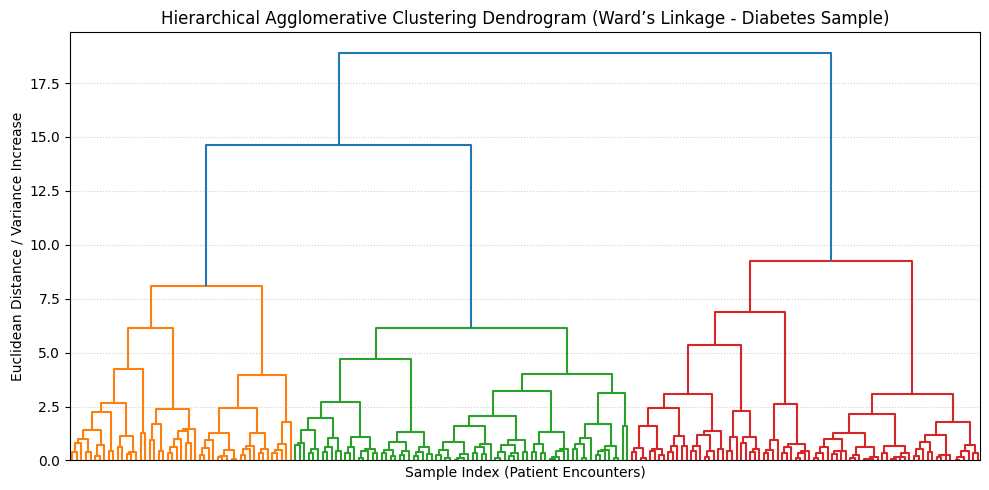

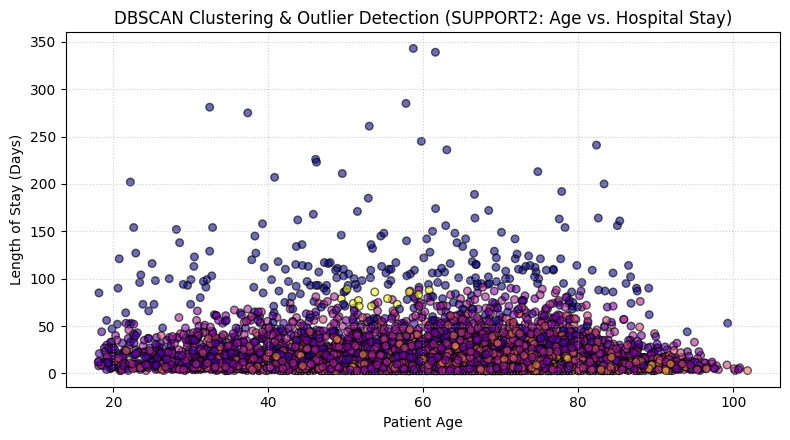

In [15]:
#visualizing HAC dendrogram using SciPy (subsampling 200 points for clear visualization)
sample_subset = X_d_scaled[:200]
linked = linkage(sample_subset, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    no_labels=True
)
plt.title('Hierarchical Agglomerative Clustering Dendrogram (Ward’s Linkage - Diabetes Sample)')
plt.xlabel('Sample Index (Patient Encounters)')
plt.ylabel('Euclidean Distance / Variance Increase')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

#visualizing DBSCAN outlier detection on SUPPORT2 dataset
plt.figure(figsize=(8, 4.5))
plt.scatter(
    df_s_subset['age'], 
    df_s_subset['slos'], 
    c=df_s_subset['DBSCAN_Cluster'], 
    cmap='plasma', 
    alpha=0.6, 
    edgecolor='k', s=30
)
plt.title('DBSCAN Clustering & Outlier Detection (SUPPORT2: Age vs. Hospital Stay)')
plt.xlabel('Patient Age')
plt.ylabel('Length of Stay (Days)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Summary:

DBSCAN Density and Noise Immunity: Unlike K-Means, which forces every point into a spherical cluster, DBSCAN uses $\epsilon$ and MinPts to discover arbitrary shapes and explicitly isolate anomalies as noise points (labeled -1). This is particularly valuable in clinical datasets where severe outlier patients (unusual lengths of stay or comorbidity combinations) would otherwise distort centroid calculations.

Hierarchical Agglomerative Clustering (HAC) & Dendrograms: HAC builds nested clusters sequentially (bottom-up agglomeration). Dendrograms visualize the step-by-step merging tree, allowing researchers to "cut" the tree at an optimal height to determine the natural number of clusters without pre-specifying $k$.

Impact of Linkage Criteria:Ward's Method minimizes the increase in total within-cluster sum of squares (variance), tending to produce balanced, spherical clusters similar to K-Means.Complete Linkage measures maximum distances between clusters, while Average Linkage uses mean pairwise distances, each capturing different structural hierarchies in healthcare resource utilization.